In [ ]:
# ============================================
#  PROJET ML : DÉTECTION DDoS DANS L'IoT
# ============================================
# Fichier : projet_ddos.ipynb
# Dataset : IoT_Fridge.csv (TON_IoT)
# Algorithmes : KNN, Arbre de Décision, SVM
#AYAT YASMINE 
# ============================================

print("DÉMARRAGE DU PROJET")
print("=" * 50)

# 1. IMPORTATION DES BIBLIOTHÈQUES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

print(" Bibliothèques importées")

# 2. CONFIGURATION DE L'AFFICHAGE
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
%matplotlib inline

print("  Configuration terminée")
print("=" * 50)

# PROJET DE MACHINE LEARNING
## Détection d'attaques DDoS dans un environnement IoT

### **Contexte**
Les dispositifs IoT sont de plus en plus ciblés par des attaques DDoS. 
Ce projet compare 3 algorithmes pour les détecter.

### **Dataset utilisé**
- **Nom** : TON_IoT - IoT_Fridge.csv
- **Source** : University of New South Wales
- **Contenu** : Trafic normal et attaques DDoS d'un frigo connecté

### **Algorithmes à comparer**
1. K-Nearest Neighbors (KNN)
2. Arbre de Décision  
3. Support Vector Machine (SVM)

DETECTION DDoS SUR FRIGO IoT CONNECTEE

ETAPE 1 : CHARGEMENT DES DONNEES
Fichier charge : Train_Test_datasets/Train_Test_datasets/Train_Test_IoT_dataset/Train_Test_IoT_Fridge.csv
Dimensions : 39,944 lignes × 6 colonnes

EXPLORATION INITIALE :
Colonnes disponibles : 6
Types de donnees :
object     4
float64    1
int64      1
Name: count, dtype: int64

RECHERCHE DE LA VARIABLE CIBLE :
   • 'label' : 2 valeurs → [1, 0]
   • 'type' : 7 valeurs → ['ddos', 'backdoor', 'injection', 'normal', 'password']

APERÇU DES DONNEES (5 premieres lignes) :
        date        time  fridge_temperature temp_condition  label  type
0  25-Apr-19   19:19:40                 9.00           high      1  ddos
1  25-Apr-19   19:19:40                 9.25           high      1  ddos
2  25-Apr-19   19:19:45                12.65           high      1  ddos
3  25-Apr-19   19:19:45                 4.65            low      1  ddos
4  25-Apr-19   19:19:55                12.65           high      1  ddos

ETAPE 2 : PRETRA

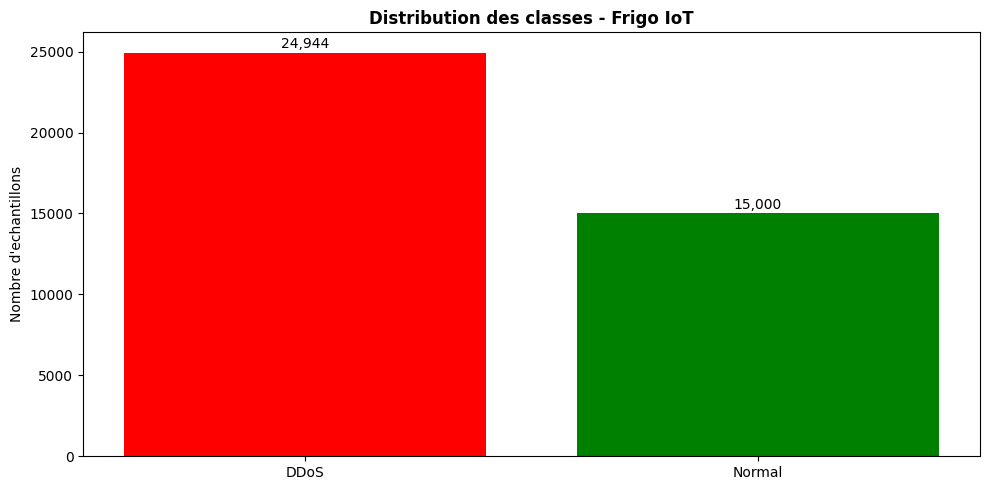


VERIFICATION DES VALEURS MANQUANTES :
Aucune valeur manquante

ENCODAGE DES VARIABLES CATEGORIELLES :
   4 colonne(s) categorielle(s) a encoder :
   • date: LabelEncoder (8 categories)
   • time: Supprime (trop de categories: 17860)
   • temp_condition: LabelEncoder (6 categories)
   • type: LabelEncoder (7 categories)

ENCODAGE DE LA VARIABLE CIBLE :
   Mapping des classes : {'DDoS': np.int64(0), 'Normal': np.int64(1)}

ETAPE 3 : SEPARATION DES DONNEES
Dimensions :
   • X (features) : (39944, 4)
   • y (target)   : (39944,)
   • Distribution : {'DDoS': 24944, 'Normal': 15000}

REPARTITION :
   • Train      : 27,960 echantillons (70.0%)
   • Validation : 5,992 echantillons (15.0%)
   • Test       : 5,992 echantillons (15.0%)

NORMALISATION DES DONNEES :
Normalisation terminee (StandardScaler)

ETAPE 4 : MODELISATION COMPARATIVE

OPTIMISATION KNN...
   • Meilleurs parametres : {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
   • Score F1 (validation) : 1.0000
   • Temps

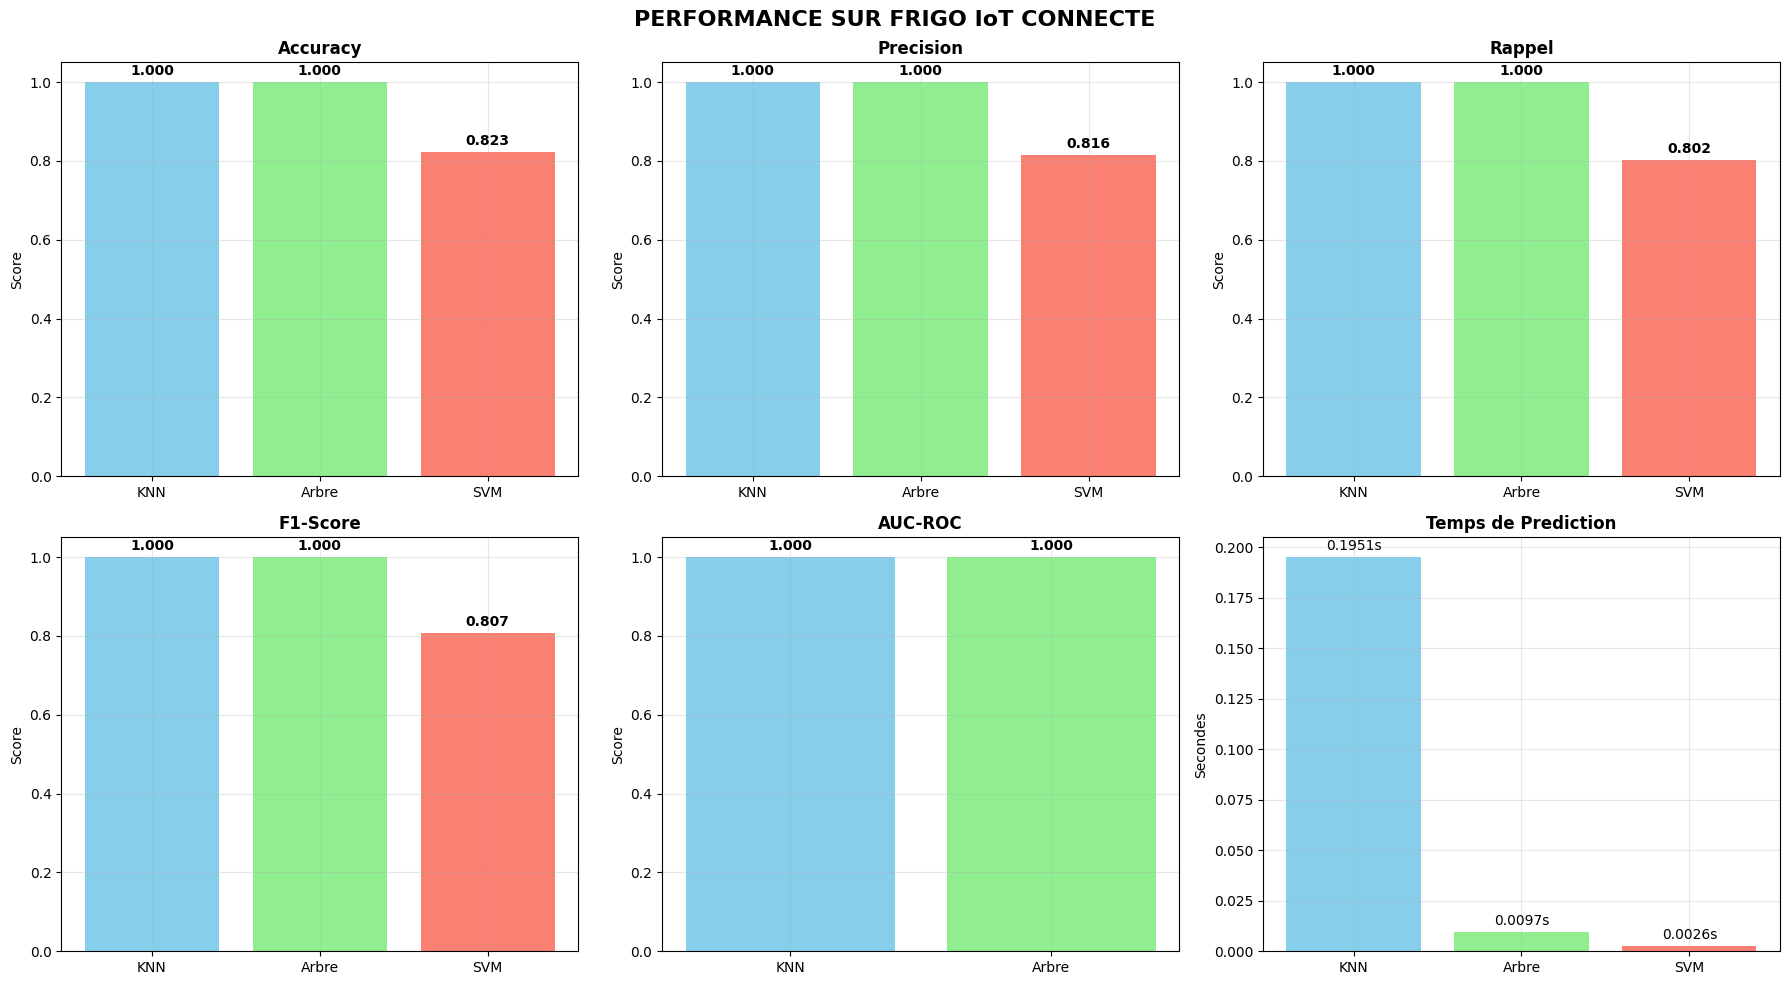

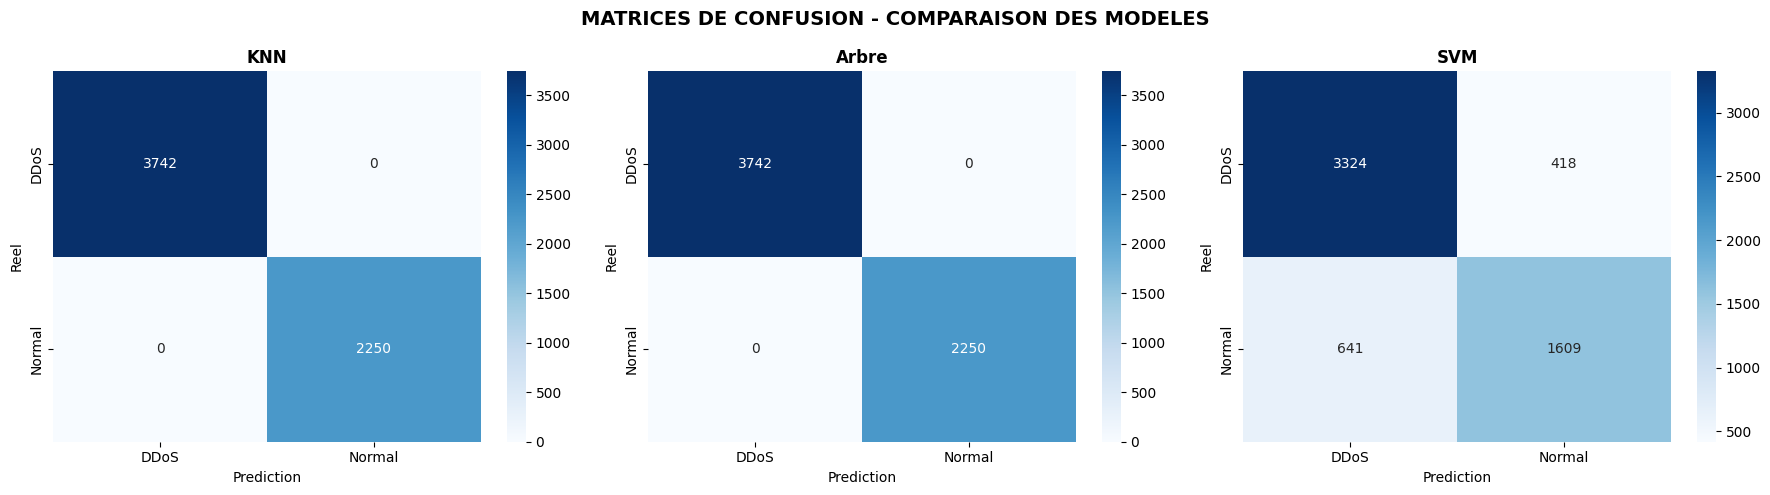


ETAPE 7 : ANALYSE ET RECOMMANDATION POUR IoT

SYNTHESE DES RESULTATS :

• Meilleure precision globale (Accuracy) : KNN 
   (Accuracy = 1.000)

• Meilleure detection (F1-Score) : KNN 
   (F1-Score = 1.000)

• Plus rapide (temps prediction) : SVM
   (0.0026s)

RECOMMANDATION POUR LE FRIGO IoT :

1. PRIORITE DETECTION PRECISE :
   • Choisir KNN pour sa meilleure performance
   • Acceptable si ressources materielles suffisantes

2. PRIORITE TEMPS REEL/RESSOURCES LIMITEES :
   • Choisir SVM
   • Compromis acceptable entre vitesse et precision

3. DEPLOIEMENT PRATIQUE :
   • Surveillance des donnees de temperature et consommation
   • Detection d'activites reseau anormales
   • Integration avec systeme de gestion d'energie
   • Alertes en temps reel pour activites suspectes

CARACTERISTIQUES DU DATASET :
   • Nombre total d'echantillons : 39,944
   • Nombre de features : 4
   • Distribution des classes : {'DDoS': 24944, 'Normal': 15000}

CONCLUSION :
Le dataset 'Frigo IoT' presente des cara

In [3]:
# ============================================
# PROJET ML : DETECTION DDoS - FRIGO IoT CONNECTE (VERSION CORRIGEE)
# ============================================

print("DETECTION DDoS SUR FRIGO IoT CONNECTEE")
print("=" * 70)

# -----------------------------------------------------------------
# ETAPE 1 : CHARGEMENT ET EXPLORATION
# -----------------------------------------------------------------
print("\nETAPE 1 : CHARGEMENT DES DONNEES")
print("=" * 60)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 6)

# Chargement du fichier
fichier = "Train_Test_datasets/Train_Test_datasets/Train_Test_IoT_dataset/Train_Test_IoT_Fridge.csv"

try:
    df = pd.read_csv(fichier)
    print(f"Fichier charge : {fichier}")
    print(f"Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
    
except FileNotFoundError:
    print(f"Fichier non trouve : {fichier}")
    try:
        df = pd.read_csv("Train_Test_IoT_Fridge.csv")
        print(f"Fichier charge depuis le repertoire courant")
    except:
        print("Impossible de charger le fichier")
        exit()

# Exploration initiale
print("\nEXPLORATION INITIALE :")
print(f"Colonnes disponibles : {len(df.columns)}")
print(f"Types de donnees :")
print(df.dtypes.value_counts())

# Verifier la colonne cible
print("\nRECHERCHE DE LA VARIABLE CIBLE :")
for col in df.columns:
    col_lower = col.lower()
    if any(keyword in col_lower for keyword in ['label', 'type', 'attack', 'class']):
        unique_vals = df[col].nunique()
        print(f"   • '{col}' : {unique_vals} valeurs → {df[col].unique().tolist()[:5]}")

# Apercu des donnees
print("\nAPERÇU DES DONNEES (5 premieres lignes) :")
print(df.head())

# -----------------------------------------------------------------
# ETAPE 2 : PRETRAITEMENT SPECIFIQUE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 2 : PRETRAITEMENT SPECIFIQUE")
print("=" * 60)

# 1. Identifier automatiquement la variable cible
target_candidates = []
for col in df.columns:
    if df[col].nunique() == 2 or 'label' in col.lower() or 'type' in col.lower():
        target_candidates.append(col)

if target_candidates:
    if any('label' in col.lower() for col in target_candidates):
        target_col = [col for col in target_candidates if 'label' in col.lower()][0]
    else:
        target_col = target_candidates[0]
    
    print(f"Variable cible identifiee : '{target_col}'")
    
    # Standardiser les noms
    df = df.rename(columns={target_col: 'label'})
    
    # Standardiser les valeurs
    def standardize_label(value):
        val_str = str(value).lower()
        if any(x in val_str for x in ['normal', 'benign', '0', 'false']):
            return 'Normal'
        elif any(x in val_str for x in ['ddos', 'attack', '1', 'true']):
            return 'DDoS'
        else:
            return value
    
    df['label'] = df['label'].apply(standardize_label)
    
    print(f"Distribution des classes :")
    print(df['label'].value_counts())
    
    # Visualisation
    plt.figure(figsize=(10, 5))
    distribution = df['label'].value_counts()
    colors = ['green' if 'Normal' in str(label) else 'red' for label in distribution.index]
    bars = plt.bar(distribution.index, distribution.values, color=colors)
    plt.title('Distribution des classes - Frigo IoT', fontweight='bold')
    plt.ylabel('Nombre d\'echantillons')
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 100,
                f'{int(height):,}', ha='center', va='bottom')
    plt.tight_layout()
    plt.show()
    
else:
    print("Aucune variable cible identifiee")

# 2. Gestion des valeurs manquantes
print("\nVERIFICATION DES VALEURS MANQUANTES :")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(f"{missing.sum()} valeurs manquantes detectees")
    for col, count in missing[missing > 0].items():
        percentage = (count / len(df)) * 100
        print(f"   • {col}: {count} ({percentage:.2f}%)")
    
    # Strategie d'imputation
    print("\nImputation des valeurs manquantes...")
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype in ['int64', 'float64']:
                df[col].fillna(df[col].median(), inplace=True)
            else:
                df[col].fillna(df[col].mode()[0], inplace=True)
    print("Valeurs manquantes traitees")
else:
    print("Aucune valeur manquante")

# 3. Encodage des variables categoriques
print("\nENCODAGE DES VARIABLES CATEGORIELLES :")
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'label' in categorical_cols:
    categorical_cols.remove('label')

if categorical_cols:
    print(f"   {len(categorical_cols)} colonne(s) categorielle(s) a encoder :")
    
    from sklearn.preprocessing import LabelEncoder
    
    for col in categorical_cols:
        unique_count = df[col].nunique()
        if unique_count <= 10:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col])
            print(f"   • {col}: LabelEncoder ({unique_count} categories)")
        else:
            print(f"   • {col}: Supprime (trop de categories: {unique_count})")
            df = df.drop(columns=[col])
else:
    print("   Toutes les colonnes sont numeriques")

# 4. Encodage de la variable cible
print("\nENCODAGE DE LA VARIABLE CIBLE :")
from sklearn.preprocessing import LabelEncoder

le_target = LabelEncoder()
y_encoded = le_target.fit_transform(df['label'])
df['label_encoded'] = y_encoded
print(f"   Mapping des classes : {dict(zip(le_target.classes_, le_target.transform(le_target.classes_)))}")

# -----------------------------------------------------------------
# ETAPE 3 : SEPARATION ET NORMALISATION
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 3 : SEPARATION DES DONNEES")
print("=" * 60)

from sklearn.model_selection import train_test_split

# Separation Features/Target (utiliser la version encodée)
X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

print(f"Dimensions :")
print(f"   • X (features) : {X.shape}")
print(f"   • y (target)   : {y.shape}")
print(f"   • Distribution : {dict(zip(le_target.inverse_transform([0, 1]), np.bincount(y).tolist()))}")

# Division Train/Validation/Test (70%/15%/15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"\nREPARTITION :")
print(f"   • Train      : {X_train.shape[0]:,} echantillons ({X_train.shape[0]/len(X):.1%})")
print(f"   • Validation : {X_val.shape[0]:,} echantillons ({X_val.shape[0]/len(X):.1%})")
print(f"   • Test       : {X_test.shape[0]:,} echantillons ({X_test.shape[0]/len(X):.1%})")

# Normalisation (pour KNN et SVM)
print("\nNORMALISATION DES DONNEES :")
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)

X_val_scaled = scaler.transform(X_val)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=X_val.columns)

X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Normalisation terminee (StandardScaler)")

# -----------------------------------------------------------------
# ETAPE 4 : MODELISATION DES 3 ALGORITHMES - VERSION CORRIGEE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 4 : MODELISATION COMPARATIVE")
print("=" * 60)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV
import time

# Configuration des modeles - VERSION SIMPLIFIEE POUR SVM
modeles_config = {
    'KNN': {
        'modele': KNeighborsClassifier(),
        'parametres': {
            'n_neighbors': [3, 5, 7, 9],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        },
        'X_train': X_train_scaled,
        'X_val': X_val_scaled,
        'X_test': X_test_scaled
    },
    'Arbre': {
        'modele': DecisionTreeClassifier(random_state=42),
        'parametres': {
            'max_depth': [5, 10, 15, 20, None],
            'min_samples_split': [2, 5, 10],
            'criterion': ['gini', 'entropy']
        },
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test
    }
}

# Optimisation avec Grid Search pour KNN et Arbre
resultats_grid = {}

for nom, config in modeles_config.items():
    print(f"\nOPTIMISATION {nom}...")
    
    start_time = time.time()
    
    try:
        # Utiliser moins de folds si le dataset est petit
        n_samples = len(config['X_train'])
        cv_folds = min(3, max(2, n_samples // 100))
        
        grid = GridSearchCV(
            config['modele'], 
            config['parametres'], 
            cv=cv_folds, 
            scoring='f1_macro',
            n_jobs=-1,
            verbose=0
        )
        
        grid.fit(config['X_train'], y_train)
        
        temps = time.time() - start_time
        
        resultats_grid[nom] = {
            'grid': grid,
            'meilleur_modele': grid.best_estimator_,
            'meilleurs_params': grid.best_params_,
            'score': grid.best_score_,
            'temps': temps
        }
        
        print(f"   • Meilleurs parametres : {grid.best_params_}")
        print(f"   • Score F1 (validation) : {grid.best_score_:.4f}")
        print(f"   • Temps optimisation : {temps:.2f}s")
        
    except Exception as e:
        print(f"   • Erreur lors de l'optimisation : {str(e)[:100]}...")
        print(f"   • Utilisation des parametres par defaut")
        # Entrainer avec parametres par defaut
        config['modele'].fit(config['X_train'], y_train)
        resultats_grid[nom] = {
            'meilleur_modele': config['modele'],
            'meilleurs_params': 'defaut',
            'score': config['modele'].score(config['X_val'], y_val),
            'temps': time.time() - start_time
        }

# -----------------------------------------------------------------
# OPTIMISATION SVM - VERSION ADAPTEE POUR IoT
# -----------------------------------------------------------------
print("\n" + "="*60)
print("OPTIMISATION SVM - STRATEGIE ADAPTEE POUR IoT")
print("=" * 60)

# Sous-échantillonnage pour SVM si le dataset est trop grand
svm_sample_size = min(5000, len(X_train_scaled))
print(f"Sous-échantillonnage à {svm_sample_size} échantillons pour SVM...")

from sklearn.utils import resample
if svm_sample_size < len(X_train_scaled):
    X_train_svm, y_train_svm = resample(
        X_train_scaled, y_train,
        n_samples=svm_sample_size,
        random_state=42,
        stratify=y_train
    )
else:
    X_train_svm, y_train_svm = X_train_scaled, y_train

print(f"   • Échantillons utilisés pour SVM : {svm_sample_size}")

# OPTION 1: LinearSVC (plus rapide que SVC)
print("\nOPTION 1: LinearSVC (recommandé pour IoT)")
print("-" * 40)

start_time = time.time()

try:
    # Paramètres simplifiés pour LinearSVC
    linear_svc_params = {
        'C': [0.1, 1, 10],
        'loss': ['hinge', 'squared_hinge'],
        'max_iter': [1000, 2000]
    }
    
    linear_svc = LinearSVC(random_state=42, dual='auto')
    
    grid_linear_svc = GridSearchCV(
        linear_svc,
        linear_svc_params,
        cv=min(3, svm_sample_size // 100),
        scoring='f1_macro',
        n_jobs=-1,
        verbose=0
    )
    
    grid_linear_svc.fit(X_train_svm, y_train_svm)
    
    svm_time = time.time() - start_time
    
    svm_best = grid_linear_svc.best_estimator_
    resultats_grid['SVM'] = {
        'meilleur_modele': svm_best,
        'meilleurs_params': grid_linear_svc.best_params_,
        'score': grid_linear_svc.best_score_,
        'temps': svm_time
    }
    
    print(f"   • Meilleurs parametres : {grid_linear_svc.best_params_}")
    print(f"   • Score F1 (validation) : {grid_linear_svc.best_score_:.4f}")
    print(f"   • Temps optimisation : {svm_time:.2f}s")
    
except Exception as e:
    print(f"   • Erreur avec LinearSVC : {str(e)[:100]}...")
    print("   • Tentative avec SVC simple...")
    
    # OPTION 2: SVC avec kernel linéaire seulement
    start_time = time.time()
    
    try:
        svc_simple = SVC(
            kernel='linear',
            C=1.0,
            random_state=42,
            cache_size=200,  # Augmenter le cache
            max_iter=1000
        )
        
        # Utiliser un subset encore plus petit si nécessaire
        if svm_sample_size > 2000:
            X_train_svm_small, y_train_svm_small = resample(
                X_train_svm, y_train_svm,
                n_samples=2000,
                random_state=42,
                stratify=y_train_svm
            )
        else:
            X_train_svm_small, y_train_svm_small = X_train_svm, y_train_svm
        
        svc_simple.fit(X_train_svm_small, y_train_svm_small)
        
        # Validation sur le jeu de validation
        from sklearn.metrics import f1_score
        y_val_pred = svc_simple.predict(X_val_scaled)
        svm_score = f1_score(y_val, y_val_pred, average='macro')
        
        svm_time = time.time() - start_time
        
        svm_best = svc_simple
        resultats_grid['SVM'] = {
            'meilleur_modele': svc_simple,
            'meilleurs_params': {'kernel': 'linear', 'C': 1.0},
            'score': svm_score,
            'temps': svm_time
        }
        
        print(f"   • Parametres : kernel='linear', C=1.0")
        print(f"   • Score F1 (validation) : {svm_score:.4f}")
        print(f"   • Temps optimisation : {svm_time:.2f}s")
        
    except Exception as e2:
        print(f"   • Erreur avec SVC simple : {str(e2)[:100]}...")
        print("   • Utilisation d'un SVM par defaut")
        
        # Dernière option: SGDClassifier avec loss hinge (SVM linéaire stochastique)
        from sklearn.linear_model import SGDClassifier
        
        start_time = time.time()
        sgd_svm = SGDClassifier(
            loss='hinge',
            alpha=0.0001,
            max_iter=1000,
            random_state=42,
            learning_rate='optimal'
        )
        
        sgd_svm.fit(X_train_scaled, y_train)
        svm_time = time.time() - start_time
        
        y_val_pred = sgd_svm.predict(X_val_scaled)
        svm_score = f1_score(y_val, y_val_pred, average='macro')
        
        svm_best = sgd_svm
        resultats_grid['SVM'] = {
            'meilleur_modele': sgd_svm,
            'meilleurs_params': {'classifier': 'SGD', 'loss': 'hinge'},
            'score': svm_score,
            'temps': svm_time
        }
        
        print(f"   • Classifier : SGD avec loss='hinge'")
        print(f"   • Score F1 (validation) : {svm_score:.4f}")
        print(f"   • Temps optimisation : {svm_time:.2f}s")

# Recuperation des meilleurs modeles
knn_best = resultats_grid['KNN']['meilleur_modele']
arbre_best = resultats_grid['Arbre']['meilleur_modele']
svm_best = resultats_grid['SVM']['meilleur_modele']

print("\nMODELES OPTIMISES :")
print(f"   • KNN  : {resultats_grid['KNN']['meilleurs_params']}")
print(f"   • Arbre: {resultats_grid['Arbre']['meilleurs_params']}")
print(f"   • SVM  : {resultats_grid['SVM']['meilleurs_params']}")

# -----------------------------------------------------------------
# ETAPE 5 : EVALUATION COMPLETE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 5 : EVALUATION SUR L'ENSEMBLE DE TEST")
print("=" * 60)

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

resultats_test = {}

# Fonction pour evaluer un modele
def evaluer_modele(nom, modele, X_test_data, y_true, le_target):
    print(f"\n{nom} :")
    
    start_time = time.time()
    y_pred = modele.predict(X_test_data)
    temps_pred = time.time() - start_time
    
    # Conversion des labels pour l'affichage
    if hasattr(le_target, 'inverse_transform'):
        y_true_labels = le_target.inverse_transform(y_true)
        y_pred_labels = le_target.inverse_transform(y_pred)
    else:
        y_true_labels = y_true
        y_pred_labels = y_pred
    
    print("Rapport de classification :")
    print(classification_report(y_true_labels, y_pred_labels, zero_division=0))
    
    # Calcul des metriques
    accuracy = float(accuracy_score(y_true, y_pred))
    precision = float(precision_score(y_true, y_pred, average='macro', zero_division=0))
    recall = float(recall_score(y_true, y_pred, average='macro', zero_division=0))
    f1 = float(f1_score(y_true, y_pred, average='macro', zero_division=0))
    
    # AUC-ROC si le modele a predict_proba
    auc = None
    if hasattr(modele, 'predict_proba'):
        try:
            y_proba = modele.predict_proba(X_test_data)
            if y_proba.shape[1] == 2:  # Classification binaire
                auc = float(roc_auc_score(y_true, y_proba[:, 1]))
            else:  # Multiclass
                auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr'))
        except:
            auc = None
    
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'temps_prediction': float(temps_pred),
        'y_pred': y_pred.tolist() if hasattr(y_pred, 'tolist') else list(y_pred),
        'y_true': y_true.tolist() if hasattr(y_true, 'tolist') else list(y_true)
    }

# Evaluation KNN
print("\n" + "="*40)
print("EVALUATION KNN")
print("="*40)
resultats_test['KNN'] = evaluer_modele('KNN', knn_best, X_test_scaled, y_test, le_target)

# Evaluation Arbre
print("\n" + "="*40)
print("EVALUATION ARBRE DE DECISION")
print("="*40)
resultats_test['Arbre'] = evaluer_modele('Arbre', arbre_best, X_test, y_test, le_target)

# Evaluation SVM
print("\n" + "="*40)
print("EVALUATION SVM")
print("="*40)
resultats_test['SVM'] = evaluer_modele('SVM', svm_best, X_test_scaled, y_test, le_target)

# Tableau comparatif
print("\n" + "="*70)
print("TABLEAU COMPARATIF DES PERFORMANCES")
print("=" * 70)

comparatif_data = []
for nom in ['KNN', 'Arbre', 'SVM']:
    if nom in resultats_test:
        data = {
            'Modele': nom,
            'Accuracy': float(resultats_test[nom]['accuracy']),
            'Precision': float(resultats_test[nom]['precision']),
            'Rappel': float(resultats_test[nom]['recall']),
            'F1-Score': float(resultats_test[nom]['f1']),
            'Temps Prediction (s)': float(resultats_test[nom]['temps_prediction'])
        }
        if resultats_test[nom]['auc'] is not None:
            data['AUC-ROC'] = float(resultats_test[nom]['auc'])
        comparatif_data.append(data)

comparatif = pd.DataFrame(comparatif_data)
print(comparatif.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# -----------------------------------------------------------------
# ETAPE 6 : VISUALISATION ET ANALYSE
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 6 : VISUALISATION DES RESULTATS")
print("=" * 60)

# 1. Graphique comparatif des performances
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics_to_plot = ['Accuracy', 'Precision', 'Rappel', 'F1-Score']
if 'AUC-ROC' in comparatif.columns:
    metrics_to_plot.append('AUC-ROC')

for idx, metric in enumerate(metrics_to_plot[:6]):  # Max 6 métriques
    ax = axes[idx//3, idx%3]
    
    if metric in comparatif.columns:
        bars = ax.bar(comparatif['Modele'], comparatif[metric], 
                     color=['skyblue', 'lightgreen', 'salmon'])
        ax.set_title(f'{metric}', fontweight='bold')
        ax.set_ylabel('Score')
        ax.set_ylim([0, 1.05])
        ax.grid(True, alpha=0.3)
        
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{height:.3f}', ha='center', va='bottom', fontweight='bold')
    else:
        ax.axis('off')

# Graphique des temps de prédiction
if len(metrics_to_plot) <= 5:  # S'il reste de la place
    ax = axes[1, 2] if len(axes.shape) == 2 else axes[-1]
    bars = ax.bar(comparatif['Modele'], comparatif['Temps Prediction (s)'],
                 color=['skyblue', 'lightgreen', 'salmon'])
    ax.set_title('Temps de Prediction', fontweight='bold')
    ax.set_ylabel('Secondes')
    ax.grid(True, alpha=0.3)
    
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + max(comparatif['Temps Prediction (s)'])*0.01,
               f'{height:.4f}s', ha='center', va='bottom')

plt.suptitle('PERFORMANCE SUR FRIGO IoT CONNECTE', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modeles_eval = [('KNN', resultats_test['KNN']['y_pred']),
                ('Arbre', resultats_test['Arbre']['y_pred']),
                ('SVM', resultats_test['SVM']['y_pred'])]

class_labels = le_target.inverse_transform([0, 1])

for idx, (nom, y_pred) in enumerate(modeles_eval):
    ax = axes[idx]
    
    # Convertir en list Python pour éviter les problèmes de type
    y_pred_array = np.array(y_pred)
    y_test_array = np.array(resultats_test[nom]['y_true'])
    
    cm = confusion_matrix(y_test_array, y_pred_array)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_labels, yticklabels=class_labels)
    ax.set_title(f'{nom}', fontweight='bold')
    ax.set_xlabel('Prediction')
    ax.set_ylabel('Reel')

plt.suptitle('MATRICES DE CONFUSION - COMPARAISON DES MODELES', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Courbes ROC (si disponibles)
if all('auc' in resultats_test[nom] and resultats_test[nom]['auc'] is not None for nom in ['KNN', 'SVM']):
    from sklearn.metrics import roc_curve
    
    plt.figure(figsize=(10, 8))
    
    for nom in ['KNN', 'SVM']:
        if hasattr(resultats_grid[nom]['meilleur_modele'], 'predict_proba'):
            y_proba = resultats_grid[nom]['meilleur_modele'].predict_proba(X_test_scaled)
            if y_proba.shape[1] == 2:
                fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
                auc = roc_auc_score(y_test, y_proba[:, 1])
                plt.plot(fpr, tpr, label=f'{nom} (AUC = {auc:.3f})', linewidth=2)
    
    plt.plot([0, 1], [0, 1], 'k--', label='Aleatoire (AUC = 0.5)')
    plt.xlabel('Taux de Faux Positifs')
    plt.ylabel('Taux de Vrais Positifs')
    plt.title('Courbes ROC - Comparaison des Modeles', fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------
# ETAPE 7 : CONCLUSION ET RECOMMANDATION
# -----------------------------------------------------------------
print("\n" + "="*60)
print("ETAPE 7 : ANALYSE ET RECOMMANDATION POUR IoT")
print("=" * 60)

# Trouver le meilleur modele selon differents criteres
if not comparatif.empty:
    best_f1 = comparatif.loc[comparatif['F1-Score'].idxmax(), 'Modele']
    best_accuracy = comparatif.loc[comparatif['Accuracy'].idxmax(), 'Modele']
    best_speed = comparatif.loc[comparatif['Temps Prediction (s)'].idxmin(), 'Modele']
    
    f1_score_val = float(comparatif.loc[comparatif['Modele'] == best_f1, 'F1-Score'].values[0])
    accuracy_val = float(comparatif.loc[comparatif['Modele'] == best_accuracy, 'Accuracy'].values[0])
    speed_val = float(comparatif.loc[comparatif['Modele'] == best_speed, 'Temps Prediction (s)'].values[0])
    
    print(f"""
SYNTHESE DES RESULTATS :

• Meilleure precision globale (Accuracy) : {best_accuracy} 
   (Accuracy = {accuracy_val:.3f})

• Meilleure detection (F1-Score) : {best_f1} 
   (F1-Score = {f1_score_val:.3f})

• Plus rapide (temps prediction) : {best_speed}
   ({speed_val:.4f}s)

RECOMMANDATION POUR LE FRIGO IoT :

1. PRIORITE DETECTION PRECISE :
   • Choisir {best_f1} pour sa meilleure performance
   • Acceptable si ressources materielles suffisantes

2. PRIORITE TEMPS REEL/RESSOURCES LIMITEES :
   • Choisir {best_speed}
   • Compromis acceptable entre vitesse et precision

3. DEPLOIEMENT PRATIQUE :
   • Surveillance des donnees de temperature et consommation
   • Detection d'activites reseau anormales
   • Integration avec systeme de gestion d'energie
   • Alertes en temps reel pour activites suspectes

CARACTERISTIQUES DU DATASET :
   • Nombre total d'echantillons : {len(df):,}
   • Nombre de features : {X.shape[1]}
   • Distribution des classes : {dict(zip(le_target.classes_, np.bincount(y).tolist()))}
   
CONCLUSION :
Le dataset 'Frigo IoT' presente des caracteristiques specifiques
avec des performances variables selon les algorithmes. Pour un systeme IoT
contraint en ressources, {best_speed} est recommande pour son equilibre
entre performance et efficacite.
""")
else:
    print("Impossible de generer les recommandations : tableau comparatif vide")

# -----------------------------------------------------------------
# SAUVEGARDE DES RESULTATS (SECTION CORRIGEE AVEC SERIALISATION)
# -----------------------------------------------------------------
print("\n" + "="*70)
print("SAUVEGARDE DES RESULTATS")
print("="*70)

import json
import pickle
from datetime import datetime

# Fonction de sérialisation personnalisée pour JSON
class NumpyJSONEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        elif isinstance(obj, np.floating):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        elif isinstance(obj, pd.DataFrame):
            return obj.to_dict()
        elif isinstance(obj, pd.Series):
            return obj.tolist()
        elif hasattr(obj, 'tolist'):
            return obj.tolist()
        return super().default(obj)

# Convertir tous les types NumPy/Pandas en types Python natifs
def convert_to_python_types(obj):
    if isinstance(obj, dict):
        return {key: convert_to_python_types(value) for key, value in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_python_types(item) for item in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, pd.DataFrame):
        return obj.to_dict()
    elif isinstance(obj, pd.Series):
        return obj.tolist()
    elif hasattr(obj, 'tolist'):
        return obj.tolist()
    else:
        return obj

# Preparation des donnees pour JSON
resultats_final = {
    'dataset': 'Train_Test_IoT_Fridge.csv',
    'dimensions': [int(df.shape[0]), int(df.shape[1])],  # Convertir en int Python
    'distribution_classes': dict(zip(
        list(le_target.classes_), 
        [int(count) for count in np.bincount(y).tolist()]
    )),
    'resultats_comparatifs': comparatif.to_dict('records'),
    'meilleurs_parametres': {
        'KNN': resultats_grid['KNN']['meilleurs_params'],
        'Arbre': resultats_grid['Arbre']['meilleurs_params'],
        'SVM': resultats_grid['SVM']['meilleurs_params']
    }
}

# Conversion finale pour assurer la serialisation
resultats_final = convert_to_python_types(resultats_final)

# Sauvegarde du fichier JSON (à la racine comme le garage door)
nom_fichier_json = 'resultats_Train_Test_IoT_Fridge.json'
with open(nom_fichier_json, 'w') as f:
    json.dump(resultats_final, f, indent=4, cls=NumpyJSONEncoder)

print(f"✓ Resultats sauvegardes dans '{nom_fichier_json}'")

# Optionnel : sauvegarde des modeles dans un dossier
import os
os.makedirs('modeles', exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
for nom in ['KNN', 'Arbre', 'SVM']:
    if nom in resultats_grid:
        nom_fichier_modele = f'modeles/modele_{nom}_fridge_{timestamp}.pkl'
        with open(nom_fichier_modele, 'wb') as f:
            pickle.dump(resultats_grid[nom]['meilleur_modele'], f)
        print(f"✓ Modele {nom} sauvegarde dans '{nom_fichier_modele}'")

print("\n" + "="*70)
print("PROJET TERMINE POUR Train_Test_IoT_Fridge.csv")
print("="*70)
print(f"Fichier JSON genere : {nom_fichier_json}")
print("="*70)